# Этап 9. Диагностика замороженных финальных моделей пробного обучения

Письмо 14.11.2026, п. 3. Код: `rssrl/diagnostics.py` (прогон и сводка), `rssrl/manifest.py` (контрольные суммы и привязка моделей к конфигам). Проверки: `tests/test_diagnostics.py`, `tests/test_manifest.py`.

**Что это и что нет.** 4 финальные модели пробного обучения (`results/pilot_training/models_manifest.csv`: 2 типа — «с базовым фильтром» / «без фильтра» — × 2 seed обучения) исполняются в двух режимах — с фильтром и без — независимо от того, как они обучались: перекрестное исполнение отделяет поведение самой политики от непосредственной работы защиты. Это **описательная диагностика** (как `describe_2x2` в `rssrl/stats.py`): без p-значений и знаков, выводов о механизме привыкания не делает.

Сцены — **номинальный режим** (нарушителя нет, фон контролируемого следования, то же, на чем модели обучались и оценивались), отдельный общий набор из 100 сцен, не пересекающийся ни со сценами обучения, ни со сценами оценки во время обучения (`DIAG_SEED_OFFSET`). В номинальном режиме с фильтром частота столкновений ожидаемо около нуля (`tests/test_nominal.py`) — здесь это не измеряется заново, а непрерывные показатели (скорость, зазор/d_min, доля времени вмешательства фильтра, частоты действий политики) — вот что действительно различает политики и режимы исполнения.

**Две оговорки для статьи (письмо 14.11), которые нужно сохранить и здесь:** досрочное окончание эпизода не равнозначно столкновению (это разные категории исхода, см. `classify_outcome`); полный эпизод длиной 40 с сам по себе не исключает столкновение на последнем шаге — `collision` в таблице ниже проверяется отдельно, а не выводится из длины эпизода.

In [1]:
import sys
sys.path.insert(0, '..')
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.diagnostics import ACTION_NAMES, summarize

RES = Path('..') / 'results'
FIG = RES / 'figures'
DIAG = RES / 'pilot_diag'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
manifest = pd.read_csv(RES / 'pilot_training' / 'models_manifest.csv')
manifest[['run', 'shield', 'seed', 'num_timesteps', 'sha256']]

,run,shield,seed,num_timesteps,sha256
0,shield1_seed0,True,0,102000,52c69eff55ce3780990444227b3c3ae1d6be883758229b...
1,shield1_seed1,True,1,102000,aec425d26e5e69d29b3745a91d65a851d0a335388c1e7d...
2,shield0_seed0,False,0,102000,a8c481dd7447c02a61eecee27c08c8d4145eab8922abf2...
3,shield0_seed1,False,1,102000,79e815448bc083edaa9618d3569f03814354ce44ba9ad5...


## Прогон диагностики

100 номинальных сцен × 4 модели × 2 режима исполнения = 800 эпизодов. Отдельным процессом (`python -m rssrl.diagnostics`): параллельные среды из ядра Jupyter зависают, как и в этапе 8. Готовый результат не перезаписываем.

In [2]:
if not (DIAG / 'episodes.csv').exists():
    subprocess.run([sys.executable, '-m', 'rssrl.diagnostics'], cwd='..', check=True)
episodes = pd.read_csv(DIAG / 'episodes.csv')
len(episodes)

800

## Сводка по (модель, режим исполнения)

In [3]:
summary = summarize(episodes)
summary['вариант'] = ['обучена ' + ('с фильтром' if ts else 'без фильтра') + f', seed {sd}, исполняется '
                      + ('с фильтром' if ex else 'без фильтра')
                      for ts, sd, ex in zip(summary.trained_shield, summary.trained_seed, summary.exec_shield)]
show = summary[['вариант', 'episodes', 'collision_rate', 'offroad_rate', 'mean_speed',
                'shield_frac', 'gap_ratio_median', 'gap_ratio_frac_below_1']].round(4)
show

,вариант,episodes,collision_rate,offroad_rate,mean_speed,shield_frac,gap_ratio_median,gap_ratio_frac_below_1
0,"обучена без фильтра, seed 0, исполняется без ф...",100,0.0,0.0,20.1043,0.0000,2.8846,0.0000
1,"обучена без фильтра, seed 0, исполняется с фил...",100,0.0,0.0,20.1043,0.0000,2.8846,0.0000
2,"обучена без фильтра, seed 1, исполняется без ф...",100,0.0,0.0,20.1043,0.0000,2.8846,0.0000
3,"обучена без фильтра, seed 1, исполняется с фил...",100,0.0,0.0,20.1043,0.0000,2.8846,0.0000
4,"обучена с фильтром, seed 0, исполняется без фи...",100,1.0,0.0,24.1855,0.0000,0.2106,0.9231
5,"обучена с фильтром, seed 0, исполняется с филь...",100,0.0,0.0,22.1193,0.3462,0.9938,0.5090
6,"обучена с фильтром, seed 1, исполняется без фи...",100,1.0,0.0,29.2605,0.0000,0.4588,0.9002
7,"обучена с фильтром, seed 1, исполняется с филь...",100,0.0,0.0,22.1193,0.4400,0.9378,0.6197


Как читать:
- `collision_rate` / `offroad_rate` — доля из 100 сцен. Ожидаемо около нуля при исполнении с фильтром (номинальный режим); без фильтра на исполнении зависит от того, как эта конкретная политика ведет себя без защиты.
- `shield_frac` — доля времени эпизода, когда фильтр реально тормозил (0 при исполнении без фильтра по определению).
- `gap_ratio_median`, `gap_ratio_frac_below_1` — медиана и доля времени, когда зазор до критичной машины впереди меньше d_min (быстрее формула фильтра, см. `rssrl/shield.py`): насколько консервативно или впритык едет политика.

## Скорость и запас по зазору

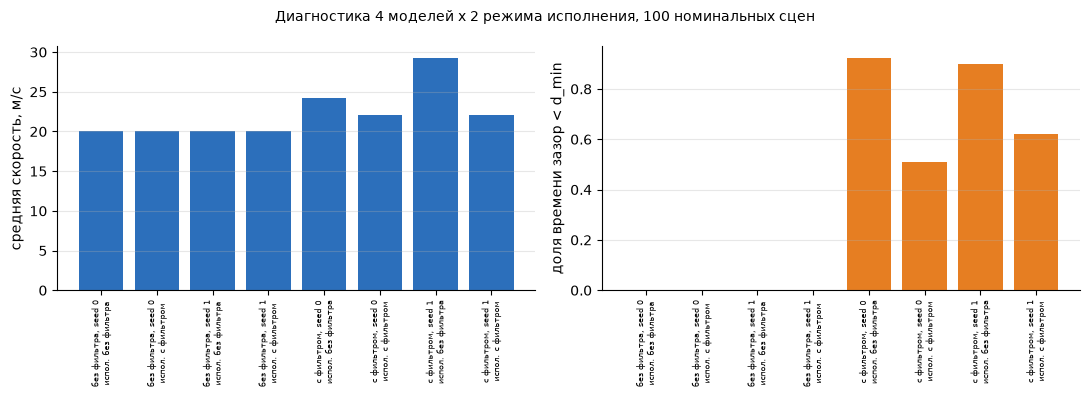

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = show['вариант'].str.replace('обучена ', '').str.replace(', исполняется', '\nиспол.')
x = np.arange(len(summary))
axes[0].bar(x, summary['mean_speed'], color='#2c6fbb')
axes[0].set_ylabel('средняя скорость, м/с')
axes[1].bar(x, summary['gap_ratio_frac_below_1'], color='#e67e22')
axes[1].set_ylabel('доля времени зазор < d_min')
for ax in axes:
    ax.set_xticks(x, labels, fontsize=6, rotation=90)
    ax.grid(axis='y', alpha=0.3)
fig.suptitle('Диагностика 4 моделей x 2 режима исполнения, 100 номинальных сцен', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '09_speed_gap.png', dpi=150)

## Частоты действий политики

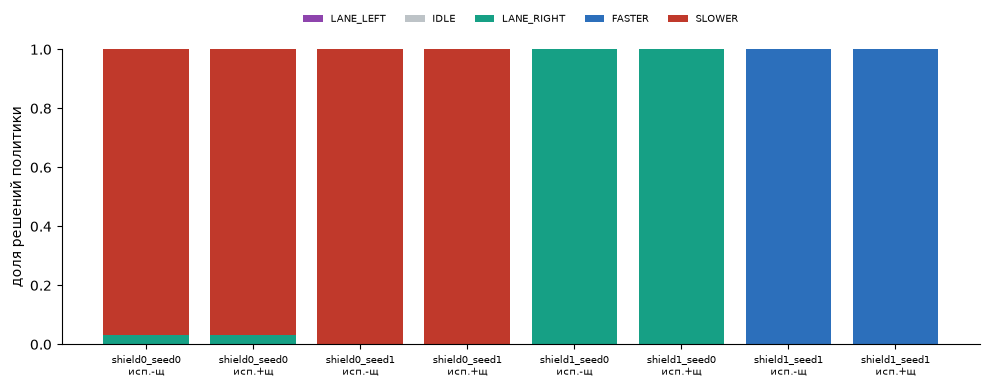

In [5]:
act_cols = [f'action_frac_{n}' for n in ACTION_NAMES.values()]
act = episodes.groupby(['run', 'exec_shield'])[act_cols].mean()
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(act))
colors = {'LANE_LEFT': '#8e44ad', 'IDLE': '#bdc3c7', 'LANE_RIGHT': '#16a085',
          'FASTER': '#2c6fbb', 'SLOWER': '#c0392b'}
xl = [f'{r}\nисп.{"+щ" if e else "-щ"}' for r, e in act.index]
for name in ACTION_NAMES.values():
    vals = act[f'action_frac_{name}'].to_numpy()
    ax.bar(range(len(act)), vals, bottom=bottom, label=name, color=colors[name])
    bottom += vals
ax.set_xticks(range(len(act)), xl, fontsize=7)
ax.set_ylabel('доля решений политики')
ax.legend(fontsize=7, frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()
fig.savefig(FIG / '09_actions.png', dpi=150)

## Ограничения (для статьи)

1. Только номинальный режим: диагностика не оценивает частоту столкновений при нарушении и не заменяет основной β-эксперимент.
2. Перекрестное исполнение описывает поведение, но само по себе не доказывает механизм привыкания политики к фильтру — для этого нужна отдельная причинная проверка на сценах с нарушением (основной эксперимент).
3. 2 seed обучения на тип — различия между seed одного типа в этой таблице дают только грубое представление о разбросе между обучениями, не точную оценку.

## Объем для семьи A (письмо 14.11, п. 4)

`rssrl/volume.py`: `family_a_power` — симуляцией, вероятность, что **всё** правило семьи A (поправка Холма по 6 сравнениям + подтверждение «хуже» на следующем β, `rssrl.stats.decide_family` + `family_threshold`) найдет именно заданный истинный порог β*. `projected_halfwidth` считает полуширину ОДНОГО интервала и такой мощности не заменяет (это и есть замечание преподавателя).

**Откуда берутся числа для симуляции.** Диагностика выше — номинальный режим, где столкновений с фильтром практически нет; она не может дать оценку разброса между обучениями для вероятности столкновения ПРИ НАРУШЕНИИ — такой величины в проекте пока ни у кого нет (основной β-эксперимент не проводился). Поэтому `policy_spread` (стандартное отклонение вероятности столкновения между политиками одного типа) и сам эффект (`baseline`, `delta`, `beta_onset`) — ПРЕДПОЛАГАЕМЫЕ параметры модели, а не оценки из данных; ниже — сетка по ним, а не одно число. Диагностика дает «полезную первичную информацию» в другом смысле (замечание преподавателя): по двум seed на тип видно, что политики одного типа уже по-разному ведут себя в номинале (видно в таблице выше) — качественное основание, что разброс между обучениями вообще есть, но не его величину для столкновений при нарушении.

In [6]:
from rssrl.volume import family_a_power, family_a_precision, step_effect

N_REP, N_BOOT = 150, 1000  # повторов симуляции и бутстрепа внутри каждого повтора
N_POLICIES = [2, 3, 5]
N_SCENES = [100, 300, 500]

### Мощность при обнаружимом эффекте (β* = 1,4, не верхняя точка сетки)

Допуск ±2 п.п. (`MARGIN`) — заранее заданная конвенция проекта для этого симуляционного исследования, не нормативный предел дорожного риска (письмо 14.11); здесь ее роль — порог практической величины внутри `decide_family`, на обнаружение статистического знака впрямую не влияет.

In [7]:
rows = []
for delta in (0.02, 0.05, 0.10):
    for spread in (0.0, 0.01):
        eff = step_effect(1.4, delta, baseline=0.03)
        df = family_a_power(eff, 1.4, N_POLICIES, N_SCENES, policy_spread=spread,
                            n_rep=N_REP, n_boot=N_BOOT, seed=hash((delta, spread)) % 2**31)
        df['эффект (дельта), п.п.'] = round(100 * delta, 1)
        rows.append(df)
power_table = pd.concat(rows, ignore_index=True)
power_table.to_csv(DIAG / 'family_a_power.csv', index=False)
power_table.pivot_table(index=['эффект (дельта), п.п.', 'разброс политик (std)'],
                        columns=['политик на тип', 'сцен'], values='мощность').round(2)

политик на тип                                  2                 3        \
сцен                                          100   300   500   100   300   
эффект (дельта), п.п. разброс политик (std)                                 
2.0                   0.00                   0.00  0.00  0.01  0.00  0.00   
                      0.01                   0.00  0.01  0.01  0.00  0.02   
5.0                   0.00                   0.01  0.31  0.81  0.01  0.63   
                      0.01                   0.00  0.27  0.55  0.01  0.39   
10.0                  0.00                   0.37  1.00  1.00  0.68  1.00   
                      0.01                   0.28  0.97  0.98  0.53  1.00   

политик на тип                                        5              
сцен                                          500   100   300   500  
эффект (дельта), п.п. разброс политик (std)                          
2.0                   0.00                   0.03  0.00  0.00  0.06  
                      0.01                   0.03  0.00  0.00  0.04  
5.0                   0.00                   0.99  0.11  0.94  1.00  
                      0.01                   0.75  0.04  0.81  0.97  
10.0                  0.00                   1.00  0.97  1.00  1.00  
                      0.01                   0.99  0.97  0.99  0.99

### Исход «не установлено» под нулевым эффектом и при ухудшении только на верхней точке сетки

Оба случая — ожидаемый, допустимый результат правила (письмо 07.11, `beta_star`): если «хуже» впервые появляется только на β = 2, подтвердить его на следующем уровне нечем. Мощность здесь — доля повторов, где правило КОРРЕКТНО возвращает «не установлено».

In [8]:
no_effect = step_effect(10.0, 0.0, baseline=0.03)  # эффекта нет ни на одном уровне сетки
top_only = step_effect(2.0, 0.08, baseline=0.03)   # «хуже» только на верхней точке
rows = []
for name, eff in [('нет эффекта', no_effect), ('эффект только при β = 2', top_only)]:
    df = family_a_power(eff, None, [3, 5], [300, 500], policy_spread=0.0, n_rep=N_REP, n_boot=N_BOOT, seed=7)
    df['случай'] = name
    rows.append(df)
none_table = pd.concat(rows, ignore_index=True)[['случай', 'политик на тип', 'сцен', 'мощность']]
none_table.to_csv(DIAG / 'family_a_power_none.csv', index=False)
none_table

,случай,политик на тип,сцен,мощность
0,нет эффекта,3,300,1.0
1,нет эффекта,3,500,1.0
2,нет эффекта,5,300,1.0
3,нет эффекта,5,500,1.0
4,эффект только при β = 2,3,300,1.0
5,эффект только при β = 2,3,500,1.0
6,эффект только при β = 2,5,300,1.0
7,эффект только при β = 2,5,500,1.0


### Точность (не мощность): полуширина совместного интервала семьи

Под нулевым эффектом — медианная полуширина СОВМЕСТНОГО интервала (`ci_simult`, уровень 1 − α/6), а не обычного 95% интервала по умолчанию (так его считает `projected_halfwidth`, и это другая величина).

In [9]:
rows = []
for n_pol in N_POLICIES:
    for n_sc in N_SCENES:
        w = family_a_precision(n_pol, n_sc, n_rep=N_REP, n_boot=N_BOOT, seed=11)
        rows.append({'политик на тип': n_pol, 'сцен': n_sc, 'точность (± п.п.)': round(100 * w, 2)})
precision_table = pd.DataFrame(rows)
precision_table.to_csv(DIAG / 'family_a_precision.csv', index=False)
precision_table.pivot(index='политик на тип', columns='сцен', values='точность (± п.п.)')

сцен,100,300,500
политик на тип,,,
2,6.50,3.67,2.85
3,5.83,3.28,2.53
5,4.70,2.67,2.06


## Выводы этапа 9

1. **Диагностика** (`results/pilot_diag/episodes.csv`, `summary.csv`): 4 финальные модели заметно различаются по непрерывным показателям (скорость, запас по зазору, частоты действий) даже в номинальном режиме, причем по-разному реагируют на отключение фильтра при исполнении — это описательный результат, не доказательство механизма привыкания.
2. **Манифест моделей** (`results/pilot_training/models_manifest.csv`): SHA-256 и фактическое число переходов (102000 у всех четырех — полный rollout после 100000) для `final_model.zip`; правило «последний чекпойнт» закреплено в CLAUDE.md для основной серии, исторические конфиги пилота не менялись.
3. **Причина завершения эпизода и вмешательства фильтра** — теперь в info `TrainingEnv` и (через `info_keywords`) в `monitor.csv` для обучения и оценки; это инфраструктура для основной серии, уже прошедший пилот не перезапускался.
4. **Объем для семьи A**: мощность всего правила (Холм + подтверждение на следующем β) и отдельно точность на уровне совместного интервала — сеткой по предполагаемому эффекту и разбросу между политиками (не оценка из данных: диагностика в номинальном режиме не может дать вероятность столкновения при нарушении). Итоговые числа и чувствительность — в тексте письма преподавателю, исход «не установлено» заранее принят как допустимый.